# Regression Project – Tehran House Price Prediction

In this project I want to predict the price of apartments in Tehran using the `housePrice.csv` dataset.

Features: `Area`, `Room`, `Parking`, `Warehouse`, `Elevator`, `Address`
Target: `Price` (Toman)

Steps:
1. Load and explore the data
2. Clean the data (missing addresses, wrong areas, duplicates)
3. Some visualization
4. Prepare features (encode Address)
5. Train regression models and compare them

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


## 2. Load the data

In [2]:
df = pd.read_csv('data/housePrice.csv')
df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


In [3]:
print(df.shape)
df.info()

(3479, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3479 non-null   object 
 1   Room        3479 non-null   int64  
 2   Parking     3479 non-null   bool   
 3   Warehouse   3479 non-null   bool   
 4   Elevator    3479 non-null   bool   
 5   Address     3456 non-null   object 
 6   Price       3479 non-null   float64
 7   Price(USD)  3479 non-null   float64
dtypes: bool(3), float64(2), int64(1), object(2)
memory usage: 146.2+ KB


`Area` is read as an object (string), not a number. Probably some values have commas in them. Let's check.

In [4]:
# rows where Area is not a simple number
df[~df['Area'].str.isnumeric()]

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
570,"3,310,000,000",2,True,True,True,Ostad Moein,3.310000e+09,110333.33
709,"16,160,000,000",3,True,True,True,Pasdaran,1.616000e+10,538666.67
807,"1,000",2,True,True,False,Damavand,7.000000e+09,233333.33
1604,"8,400,000,000",2,True,True,True,Gheitarieh,8.700000e+09,290000.00
2171,"3,600",2,False,False,False,Shahryar,9.720000e+09,324000.00
2802,"2,550,000,000",2,True,True,True,Central Janatabad,2.550000e+09,85000.00


These are the wrong areas mentioned in the question. For example 3,310,000,000 m² is obviously not an apartment area (it looks like someone typed the price in the area column).
First I convert `Area` to a number, then I remove the wrong ones.

## 3. Data cleaning

### 3.1 Convert Area to numeric

In [5]:
df['Area'] = df['Area'].str.replace(',', '')
df['Area'] = pd.to_numeric(df['Area'])
df['Area'].describe()

count    3.479000e+03
mean     8.744000e+06
std      3.167266e+08
min      3.000000e+01
25%      6.900000e+01
50%      9.000000e+01
75%      1.200000e+02
max      1.616000e+10
Name: Area, dtype: float64

### 3.2 Remove houses with wrong (very large) area

In [6]:
# look at the biggest areas
df.sort_values('Area', ascending=False).head(10)

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
709,16160000000,3,True,True,True,Pasdaran,1.616000e+10,538666.67
1604,8400000000,2,True,True,True,Gheitarieh,8.700000e+09,290000.00
570,3310000000,2,True,True,True,Ostad Moein,3.310000e+09,110333.33
2802,2550000000,2,True,True,True,Central Janatabad,2.550000e+09,85000.00
2171,3600,2,False,False,False,Shahryar,9.720000e+09,324000.00
807,1000,2,True,True,False,Damavand,7.000000e+09,233333.33
1694,929,5,True,True,False,Zafar,8.000000e+10,2666666.67
1974,900,3,True,True,False,Damavand,8.500000e+09,283333.33
573,863,2,True,True,True,Gheitarieh,7.830000e+09,261000.00
831,750,5,True,True,True,Mahmoudieh,7.500000e+10,2500000.00


Areas up to about 1000 m² can be real (big apartments in north of Tehran), but 3600 and the values in billions are wrong.
So I keep only houses with `Area <= 1000`.

In [7]:
print('before:', len(df))
df = df[df['Area'] <= 1000]
print('after :', len(df))

before: 3479
after : 3474


### 3.3 Remove houses without address

In [8]:
print(df.isnull().sum())

Area           0
Room           0
Parking        0
Warehouse      0
Elevator       0
Address       23
Price          0
Price(USD)     0
dtype: int64


In [9]:
df = df.dropna(subset=['Address'])
print('rows after removing missing address:', len(df))

rows after removing missing address: 3451


### 3.4 Remove duplicate rows

In [10]:
print('number of duplicates:', df.duplicated().sum())
df = df.drop_duplicates()
print('rows after removing duplicates:', len(df))

number of duplicates: 208
rows after removing duplicates: 3243


### 3.5 Convert True/False columns to 0/1

In [11]:
for col in ['Parking', 'Warehouse', 'Elevator']:
    df[col] = df[col].astype(int)

df = df.reset_index(drop=True)
df.head()

,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,1,1,1,Shahran,1.850000e+09,61666.67
1,60,1,1,1,1,Shahran,1.850000e+09,61666.67
2,79,2,1,1,1,Pardis,5.500000e+08,18333.33
3,95,2,1,1,1,Shahrake Qods,9.025000e+08,30083.33
4,123,2,1,1,1,Shahrake Gharb,7.000000e+09,233333.33


## 4. Exploratory Data Analysis

In [12]:
df.describe()

,Area,Room,Parking,Warehouse,Elevator,Price,Price(USD)
count,3243.000000,3243.000000,3243.000000,3243.000000,3243.000000,3.243000e+03,3.243000e+03
mean,107.976257,2.087882,0.845205,0.914277,0.785384,5.474094e+09,1.824698e+05
std,72.634990,0.765132,0.361765,0.279998,0.410619,8.271385e+09,2.757128e+05
min,30.000000,0.000000,0.000000,0.000000,0.000000,3.600000e+06,1.200000e+02
25%,70.000000,2.000000,1.000000,1.000000,1.000000,1.420000e+09,4.733333e+04
50%,90.000000,2.000000,1.000000,1.000000,1.000000,2.970000e+09,9.900000e+04
75%,121.500000,2.000000,1.000000,1.000000,1.000000,6.167500e+09,2.055833e+05
max,1000.000000,5.000000,1.000000,1.000000,1.000000,9.240000e+10,3.080000e+06


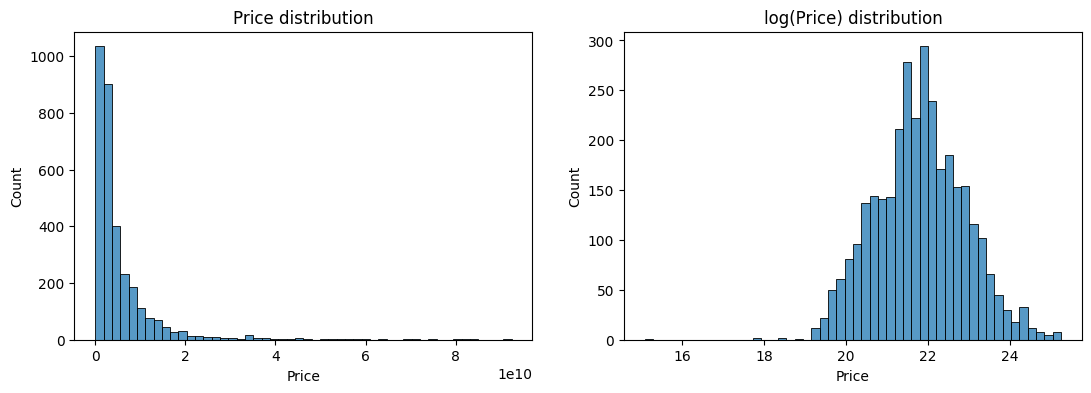

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df['Price'], bins=50, ax=ax[0])
ax[0].set_title('Price distribution')

sns.histplot(np.log(df['Price']), bins=50, ax=ax[1])
ax[1].set_title('log(Price) distribution')

plt.show()

The price is very right-skewed (a few very expensive houses). After taking the log it looks much closer to a normal distribution, so later I will also try to predict `log(Price)`.

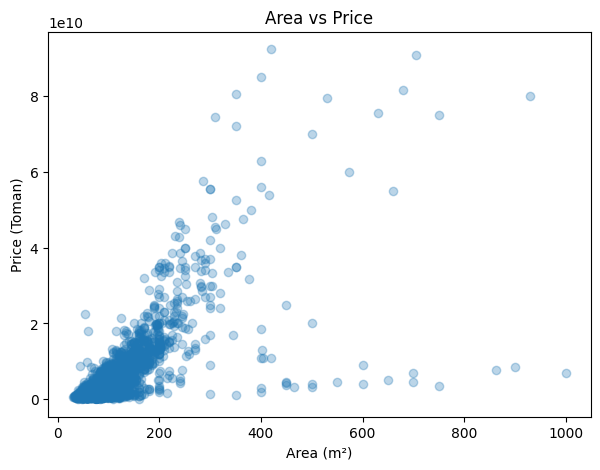

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(df['Area'], df['Price'], alpha=0.3)
plt.xlabel('Area (m²)')
plt.ylabel('Price (Toman)')
plt.title('Area vs Price')
plt.show()

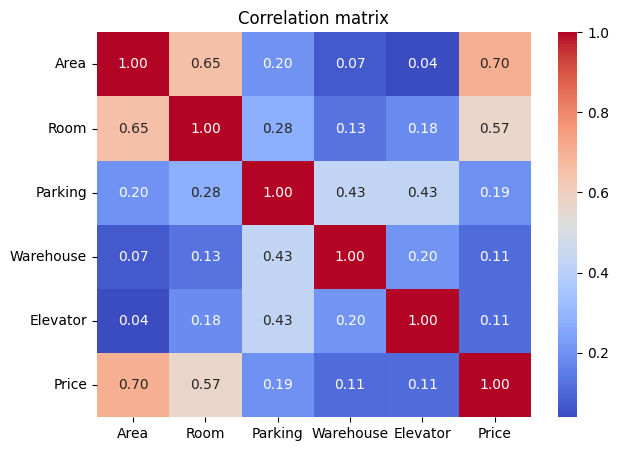

In [15]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Price']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix')
plt.show()

`Area` has the highest correlation with price, then `Room`. Parking, warehouse and elevator have smaller effect.

But in Tehran we know location is very important, so let's look at the address too.

In [16]:
print('number of different addresses:', df['Address'].nunique())

# 10 most expensive neighborhoods (average price per m²)
df['price_per_m2'] = df['Price'] / df['Area']
df.groupby('Address')['price_per_m2'].mean().sort_values(ascending=False).head(10)

number of different addresses: 192


Address
Gandhi        1.400000e+08
Vanak         1.274156e+08
Lavasan       1.172917e+08
Zaferanieh    1.137139e+08
Elahieh       1.122126e+08
Velenjak      1.116799e+08
Kamranieh     1.036243e+08
Niavaran      1.023744e+08
Farmanieh     1.010321e+08
Aqdasieh      9.228206e+07
Name: price_per_m2, dtype: float64

In [17]:
# 10 cheapest neighborhoods
df.groupby('Address')['price_per_m2'].mean().sort_values().head(10)

Address
Malard                4.166667e+06
Pishva                4.458333e+06
Varamin - Beheshti    4.666667e+06
Robat Karim           5.507102e+06
Shahedshahr           5.654070e+06
Firoozkooh            6.103896e+06
Parand                6.190705e+06
Vahidiyeh             6.523256e+06
Salehabad             6.818182e+06
Pakdasht              7.230014e+06
Name: price_per_m2, dtype: float64

The difference between neighborhoods is huge (price per m² in the most expensive areas is many times more than the cheapest ones), so Address must be used in the model.

In [18]:
# I don't need this column anymore (it uses the price itself, so it would be data leakage)
df = df.drop(columns=['price_per_m2'])

## 5. Prepare features

- `Address` is categorical, so I use **one-hot encoding** (`pd.get_dummies`).
- `Price(USD)` is just the price divided by the dollar rate, so it must NOT be used as a feature. I predict `Price` (Toman).

In [19]:
X_raw = df[['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address']]
y = df['Price']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42
)

# One-hot encode from the training addresses only, then line the test set up
# against those same columns.
# Encoding before the split would create columns for neighbourhoods that appear
# only in the test data. The model has no training rows for them, the training
# matrix ends up rank deficient, and plain OLS gives those columns arbitrary
# coefficients - one such test house is enough to destroy the score.
X_train = pd.get_dummies(X_train_raw, columns=['Address'], drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test_raw, columns=['Address'], drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print('train:', X_train.shape, ' test:', X_test.shape)


train: (2594, 186)  test: (649, 186)


I write a small function to print the metrics so I don't repeat code.

In [20]:
results = []

def evaluate(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    results.append([name, r2, mae / 1e9, rmse / 1e9])
    print(name)
    print('  R2   :', round(r2, 3))
    print('  MAE  :', round(mae / 1e9, 3), 'billion Toman')
    print('  RMSE :', round(rmse / 1e9, 3), 'billion Toman')

## 6. Models

### Model 1: Simple Linear Regression (only Area)

First a very simple baseline with only one feature.

In [21]:
lr_simple = LinearRegression()
lr_simple.fit(X_train[['Area']], y_train)
pred = lr_simple.predict(X_test[['Area']])

evaluate('Simple LR (Area only)', y_test, pred)
print('coefficient (price per m²):', round(lr_simple.coef_[0]), 'Toman')

Simple LR (Area only)
  R2   : 0.406
  MAE  : 2.742 billion Toman
  RMSE : 6.051 billion Toman
coefficient (price per m²): 83108627 Toman


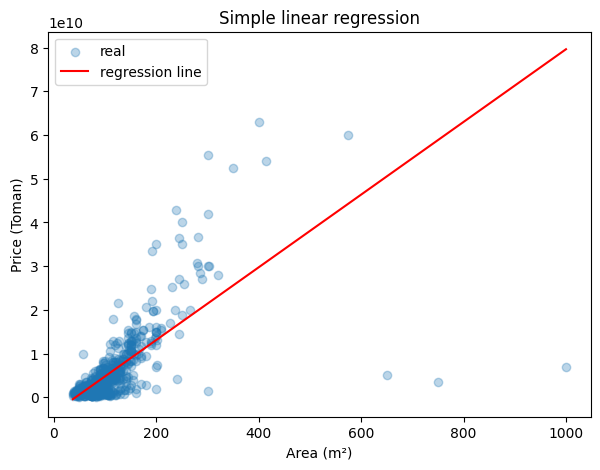

In [22]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test['Area'], y_test, alpha=0.3, label='real')
xs = np.linspace(X_test['Area'].min(), X_test['Area'].max(), 100).reshape(-1, 1)
plt.plot(xs, lr_simple.predict(pd.DataFrame(xs, columns=['Area'])), color='red', label='regression line')
plt.xlabel('Area (m²)')
plt.ylabel('Price (Toman)')
plt.legend()
plt.title('Simple linear regression')
plt.show()

### Model 2: Multiple Linear Regression (all features, without Address)

In [23]:
basic_cols = ['Area', 'Room', 'Parking', 'Warehouse', 'Elevator']

lr_multi = LinearRegression()
lr_multi.fit(X_train[basic_cols], y_train)
pred = lr_multi.predict(X_test[basic_cols])

evaluate('Multiple LR (no Address)', y_test, pred)

Multiple LR (no Address)
  R2   : 0.452
  MAE  : 2.973 billion Toman
  RMSE : 5.812 billion Toman


### Model 3: Multiple Linear Regression with Address (one-hot)

In [24]:
lr_addr = LinearRegression()
lr_addr.fit(X_train, y_train)
pred = lr_addr.predict(X_test)

evaluate('LR + Address', y_test, pred)

LR + Address
  R2   : 0.628
  MAE  : 2.153 billion Toman
  RMSE : 4.785 billion Toman


Adding the address improves the model a lot. But a linear model on raw price has a problem: the effect of location is **multiplicative** (1 m² in an expensive area adds much more than 1 m² in a cheap area), and the price is very skewed.

### Model 4: Ridge Regression on log(Price)
Here I train on `log(Price)` and then convert the prediction back with `exp`. I use Ridge (linear regression with L2 regularization) because we have ~190 dummy columns and some neighborhoods have very few houses.
I also use `log(Area)`, so the model becomes something like: `log(price) = a*log(area) + (effect of neighborhood) + ...`

In [25]:
X_train_log = X_train.copy()
X_test_log = X_test.copy()
X_train_log['Area'] = np.log(X_train_log['Area'])
X_test_log['Area'] = np.log(X_test_log['Area'])

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_log, np.log(y_train))
pred = np.exp(ridge.predict(X_test_log))

evaluate('Ridge on log(Price), alpha=1', y_test, pred)

Ridge on log(Price), alpha=1
  R2   : 0.839
  MAE  : 1.261 billion Toman
  RMSE : 3.146 billion Toman


Let me try a few values of `alpha` to see which one is better (on the training set with cross validation).

In [26]:
from sklearn.model_selection import cross_val_score

for a in [0.01, 0.1, 0.5, 1, 5, 10]:
    scores = cross_val_score(Ridge(alpha=a), X_train_log, np.log(y_train), cv=5, scoring='r2')
    print('alpha =', a, ' -> mean CV R2 (log scale):', round(scores.mean(), 4))

alpha = 0.01  -> mean CV R2 (log scale): 0.8717
alpha = 0.1  -> mean CV R2 (log scale): 0.876
alpha = 0.5  -> mean CV R2 (log scale): 0.8779
alpha = 1  -> mean CV R2 (log scale): 0.8769
alpha = 5  -> mean CV R2 (log scale): 0.8598
alpha = 10  -> mean CV R2 (log scale): 0.8408


In [27]:
best_alpha = 0.5   # best mean CV score in the output above
ridge = Ridge(alpha=best_alpha)
ridge.fit(X_train_log, np.log(y_train))
pred_ridge = np.exp(ridge.predict(X_test_log))

evaluate(f'Ridge on log(Price), alpha={best_alpha}', y_test, pred_ridge)

Ridge on log(Price), alpha=0.5
  R2   : 0.84
  MAE  : 1.253 billion Toman
  RMSE : 3.137 billion Toman


## 7. Compare the models

In [28]:
res = pd.DataFrame(results, columns=['Model', 'R2', 'MAE (billion T)', 'RMSE (billion T)'])
res.round(3)

,Model,R2,MAE (billion T),RMSE (billion T)
0,Simple LR (Area only),0.406,2.742,6.051
1,Multiple LR (no Address),0.452,2.973,5.812
2,LR + Address,0.628,2.153,4.785
3,"Ridge on log(Price), alpha=1",0.839,1.261,3.146
4,"Ridge on log(Price), alpha=0.5",0.840,1.253,3.137


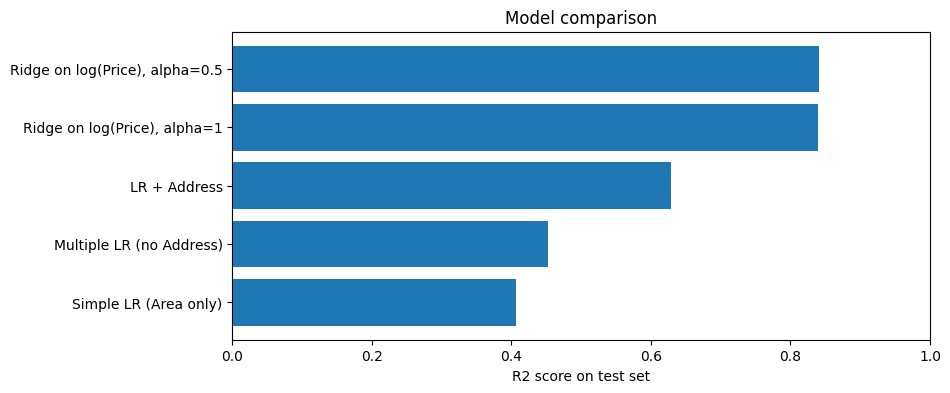

In [29]:
plt.figure(figsize=(9, 4))
plt.barh(res['Model'], res['R2'])
plt.xlabel('R2 score on test set')
plt.title('Model comparison')
plt.xlim(0, 1)

# Saved so README.md can show the result without anyone running this notebook.
plt.savefig('figures/result.png', dpi=150, bbox_inches='tight')
plt.show()

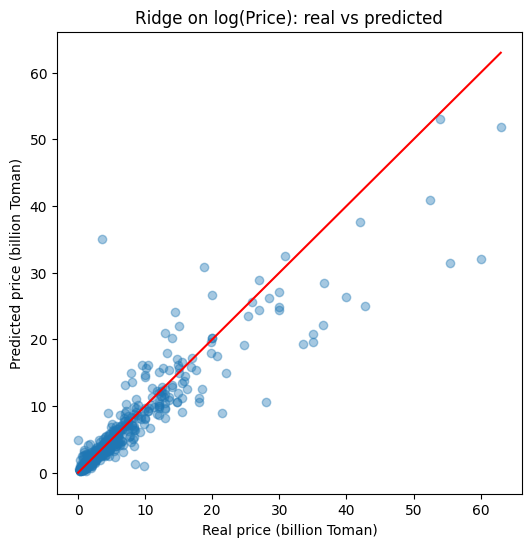

In [30]:
# real vs predicted for the best linear model
plt.figure(figsize=(6, 6))
plt.scatter(y_test / 1e9, pred_ridge / 1e9, alpha=0.4)
m = y_test.max() / 1e9
plt.plot([0, m], [0, m], color='red')
plt.xlabel('Real price (billion Toman)')
plt.ylabel('Predicted price (billion Toman)')
plt.title('Ridge on log(Price): real vs predicted')
plt.show()

## 8. Predict price for a new house

In [31]:
def predict_price(area, room, parking, warehouse, elevator, address):
    new = pd.DataFrame(0, index=[0], columns=X_train_log.columns)
    new['Area'] = np.log(area)
    new['Room'] = room
    new['Parking'] = int(parking)
    new['Warehouse'] = int(warehouse)
    new['Elevator'] = int(elevator)
    if 'Address_' + address in new.columns:
        new['Address_' + address] = 1
    price = np.exp(ridge.predict(new)[0])
    return price

p = predict_price(100, 2, True, True, True, 'Punak')
print('Predicted price:', round(p / 1e9, 2), 'billion Toman')
print('Predicted price:', round(p / 30000), 'USD')   # in this dataset 1 USD = 30,000 Toman

Predicted price: 4.38 billion Toman
Predicted price: 146081 USD


## 9. Conclusion

- The dataset had some problems: `Area` was stored as text with commas, some areas were clearly wrong (e.g. billions of m²), some houses had no address, and there were duplicate rows. I removed all of these.
- `Area` alone explains only part of the price. **Address (location) is the most important factor** after area – adding it improved R² a lot.
- Predicting `log(Price)` instead of `Price` works better, because house prices are skewed and the effect of location is multiplicative.
- The best model was **Ridge on log(Price) with alpha=0.5** (R² ≈ 0.84 on the test set, MAE ≈ 1.25 billion Toman). Going from the simple model (R² ≈ 0.41) to this one roughly halved the average error.
- RMSE is still much larger than MAE, which means the model makes some big errors on very expensive houses (north of Tehran).
- Possible improvements: more features (building age, floor), removing more outliers in price, trying non-linear models.